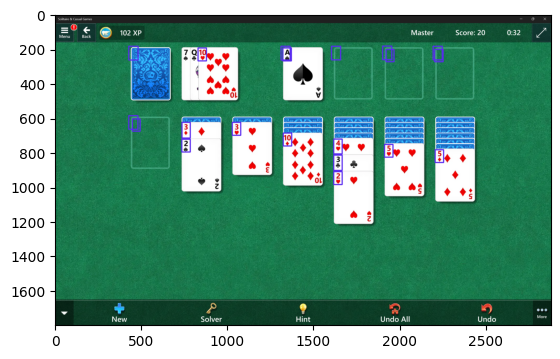

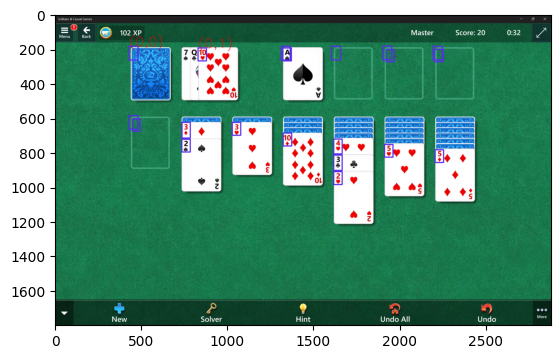

In [84]:

import cv2 as cv
import matplotlib.pyplot as plot
import numpy as np


im=cv.imread("K2.png")
# im = cv.resize(im, (2880,1800))

ig=cv.cvtColor(im,cv.COLOR_RGB2GRAY)
ig=cv.bilateralFilter(ig,5,15,15)
linesImg=np.zeros(ig.shape,np.uint8)
dst = cv.Canny(ig, 100, 200)
ig=cv.adaptiveThreshold(dst,255,cv.ADAPTIVE_THRESH_GAUSSIAN_C,cv.THRESH_BINARY_INV,11,2)

cv.imwrite("hi.png",ig)
contours,thresh=cv.findContours(ig,cv.RETR_LIST,cv.CHAIN_APPROX_SIMPLE)
maxR=0
c=0
avgA=0
rects=[]
for cnt in contours:
    x,y,w,h = cv.boundingRect(cnt)
    maxR=max(maxR,w*h)
    avgA+=w*h
    c+=1
    if (0.7<w/h<0.8) and (h>=im.shape[0]/10 or w>=im.shape[1]/12.5) :
        #cv.rectangle(im,(x,y),(x+w,y+h),(0,255,0),2)
        cv.rectangle(im,(x-5,y),(x+w//5,y+h//4),(240, 43, 89),5)
        rects.append((x-5,y,x+w//5,y+h//4))
    elif (h>=im.shape[0]/30 or w>=im.shape[1]/37.5) and (2.4<w/h<2.6):
        #cv.rectangle(im,(x,y),(x+w,y+h),(0,255,0),2)
        cv.rectangle(im,(x-5,y),(x+w//5,y+h),(240, 43, 89),5)
        rects.append((x-5,y,x+w//5,y+h//4))
    # elif cv.contourArea(cnt)>2000 and cv.approxPolyDP(cnt,epsilon,True).size>=4:
    #     cv.rectangle(im,(x,y),(x+w,y+h),(255,0,0),2)
rects_sorted = sorted(rects, key=lambda r: (r[0], r[1]))
im=cv.cvtColor(im,cv.COLOR_BGR2RGB)
plot.figure()
plot.imshow(im)
im=cv.cvtColor(im,cv.COLOR_RGB2BGR)
cv.imwrite("bye.png",im)


deck_x, deck_y,_,_ = rects_sorted[0]
Col1_x, Col2,_,_ = rects_sorted[1]
offsetXForDrawn=0
cv.putText(im, f"({0},{0})", (deck_x, deck_y),
    cv.FONT_HERSHEY_SIMPLEX, 2.6, (0,0,255), 2)
for i in rects_sorted:
    r=0
    c=0
    if deck_y<i[1]<=deck_y+20:
        if(deck_x<=i[0]<=deck_x+450):
            c=1
            cv.putText(im, f"({r},{c})", (i[0], i[1]),
               cv.FONT_HERSHEY_SIMPLEX, 2.6, (0,0,255), 2)
    # if i[0]!=deck_x:
    #     if i[y]==

ROWS = 7
COLS = 21
matrix = [["." for _ in range(COLS)] for _ in range(ROWS)]
im=cv.cvtColor(im,cv.COLOR_BGR2RGB)
plot.figure()
plot.imshow(im)


the code successfuly marks the rank and suit region of all cards on the board except when the board is longer than it is wide. this can be fixed by foceing the window to be full screened. This is only based on test images. 